# Homework 5
> **Author:** Elias Schweighuber
> **Course:** HEO


In [1]:
import json
import os
import random
import time
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import clear_output


## 1. Encodings
Make a literature search, regarding genetic operators (selection, crossover, mutation) for the traveling salesman problem. Present one selection, crossover, and mutation operator. Draw a sample encoding on the board and explain the idea of the operators. Do not explain any operators presented in the lecture.

### Sample Encoding (Path Representation)
- A tour is encoded as a permutation of city IDs representing the visiting order:
  - Parent 1: `[1, 2, 3, 4, 5, 6]`
  - Parent 2: `[3, 5, 1, 6, 2, 4]`

### 1. Selection Operator: Stochastic Universal Sampling (SUS)
- **Idea:** Instead of spinning a roulette wheel *N* times with a single pointer, SUS uses *N* equally spaced pointers in a single spin (spaced by *Total Fitness / N*).
- **Advantage:** It guarantees zero bias and minimum spread, giving weaker individuals a fair chance and preventing super-individuals from taking over immediately.

### 2. Crossover Operator: Position-Based Crossover (POS)
- **Idea:**
  1. Randomly select a set of positions (not a contiguous block) from Parent 1 and copy those cities to the exact same positions in the child.
  2. Fill the remaining empty positions with the missing cities in the order they appear in Parent 2.
- **Example:**
  - Parent 1: `[1, 2, 3, 4, 5, 6]`, selected positions: 2nd, 4th, 5th -> `[-, 2, -, 4, 5, -]`
  - Parent 2: `[3, 5, 1, 6, 2, 4]`, remaining cities in order: `3, 1, 6`
  - Child: `[3, 2, 1, 4, 5, 6]`

### 3. Mutation Operator: Scramble Mutation
- **Idea:** Select a random subset of the tour and randomly shuffle the cities within those positions.
- **Example:**
  - Before: `[1, | 2, 3, 4, 5 |, 6]`
  - After shuffling segment: `[1, | 4, 2, 5, 3 |, 6]`


## Second Exercise TSP Classes

In [2]:
class Point:
    def __init__(self, point_id, x, y):
        self.id = point_id
        self.x = x
        self.y = y

    def __repr__(self):
        return f"Point({self.id}, {self.x}, {self.y})"

    def to_dict(self):
        return {"id": self.id, "x": self.x, "y": self.y}

    @classmethod
    def from_dict(cls, data):
        return cls(data["id"], data["x"], data["y"])


In [3]:
class Tour:
    def __init__(self, points):
        self.points = points.copy()

    def generate_random(self):
        random.shuffle(self.points)

    def total_distance(self):
        # sqrt(x^2 + y^2)
        # modulo is for last point to first
        return sum(
            ((self.points[i].x - self.points[(i + 1) % len(self.points)].x)**2 +
             (self.points[i].y - self.points[(i + 1) % len(self.points)].y)**2)**0.5
            for i in range(len(self.points))
        )

    def plot(self, title="Tour"):
        fig, ax = plt.subplots(figsize=(10, 8))

        xs = [p.x for p in self.points] + [self.points[0].x]
        ys = [p.y for p in self.points] + [self.points[0].y]

        ax.plot(xs, ys, marker='o', linestyle='-', color='dodgerblue', markersize=6)
        ax.plot([xs[0]], [ys[0]], marker='s', color='green', markersize=9, label='Start Point')
        ax.legend()
        ax.set_title(title)
        ax.set_xlabel("X Coordinate")
        ax.set_ylabel("Y Coordinate")
        ax.set_xlim(-50, 1050)
        ax.set_ylim(-50, 1050)
        ax.grid(True, linestyle='--', alpha=0.6)
        plt.show()


## 2. Genetic Algorithm
Implement a genetic algorithm for the TSP instances from your second exercise. Implement a Tournament selection, Ordered Crossover and swap mutation.


### hw1 methods

In [4]:
HW1_DIR = "../hw1"

def load_instances(filename=os.path.join(HW1_DIR, "instances.json")):
    with open(filename, "r", encoding="utf-8") as f:
        data = json.load(f)
    return [[Point.from_dict(p) for p in pts] for pts in data.values()]

def save_tour_to_file(tour, filepath):
    os.makedirs(os.path.dirname(filepath), exist_ok=True)
    with open(filepath, "w", encoding="utf-8") as f:
        f.write(f"{tour.total_distance():.2f}\n\n")
        for p in tour.points:
            f.write(f"{p.id} {float(p.x):.1f} {float(p.y):.1f}\n")

def read_tour_result(filepath):
    with open(filepath, "r", encoding="utf-8") as f:
        lines = [line.strip() for line in f if line.strip()]
    dist = float(lines[0])
    points = [Point(int(p[0]), float(p[1]), float(p[2])) for p in (line.split() for line in lines[1:])]
    return dist, points

def read_all_tour_results(folder_path):
    files = sorted(
        [f for f in os.listdir(folder_path) if f.startswith("tour_instance_")],
        key=lambda f: int(f.split("_")[-1].split(".")[0])
    )
    results = []
    for fn in files:
        iid = int(fn.split("_")[-1].split(".")[0])
        dist, pts = read_tour_result(os.path.join(folder_path, fn))
        results.append({
            "instance_id": iid,
            "filename": fn,
            "distance": dist,
            "points": pts,
            "tour": Tour(pts)
        })
    return results


In [5]:
def tournament_selection(population, distances, k=3):
    selected_indices = random.sample(range(len(population)), k)
    best_idx = min(selected_indices, key=lambda i: distances[i])
    return population[best_idx]

def ordered_crossover(parent1, parent2):
    size = len(parent1)
    start, end = sorted(random.sample(range(size), 2))
    child = [None] * size
    child[start:end + 1] = parent1[start:end + 1]

    copied_ids = {p.id for p in child[start:end + 1]}
    remaining = [p for p in parent2 if p.id not in copied_ids]

    rem_idx = 0
    for i in range(size):
        if child[i] is None:
            child[i] = remaining[rem_idx]
            rem_idx += 1
    return child

def swap_mutation(individual, mutation_chance=0.05):
    mutated = individual.copy()
    if random.random() < mutation_chance:
        i, j = random.sample(range(len(mutated)), 2)
        mutated[i], mutated[j] = mutated[j], mutated[i]
    return mutated

def genetic_algorithm(points, pop_size=100, generations=1000, mutation_chance=0.05, elite_size=1, tournament_k=3):
    population = [random.sample(points, len(points)) for _ in range(pop_size)]

    for _ in range(generations):
        distances = [Tour(ind).total_distance() for ind in population]
        sorted_indices = sorted(range(pop_size), key=lambda i: distances[i])

        new_population = [population[i].copy() for i in sorted_indices[:elite_size]]

        while len(new_population) < pop_size:
            p1 = tournament_selection(population, distances, k=tournament_k)
            p2 = tournament_selection(population, distances, k=tournament_k)
            child = ordered_crossover(p1, p2)
            child = swap_mutation(child, mutation_chance)
            new_population.append(child)

        population = new_population

    distances = [Tour(ind).total_distance() for ind in population]
    best_idx = min(range(pop_size), key=lambda i: distances[i])
    return Tour(population[best_idx])


In [6]:
random.seed(42)
instances = load_instances()
ga_folder = os.path.join(HW1_DIR, "results", "genetic_algorithm")
os.makedirs(ga_folder, exist_ok=True)

ga_dists = []
for idx, pts in enumerate(instances, start=1):
    best_tour = genetic_algorithm(pts, pop_size=100, generations=1000, mutation_chance=0.05, elite_size=1, tournament_k=3)
    dist = best_tour.total_distance()
    save_tour_to_file(best_tour, os.path.join(ga_folder, f"tour_instance_{idx}.txt"))
    ga_dists.append(dist)
    print(f"tour_instance_{idx:02d} | Distance={dist:4.0f}")


tour_instance_01 | Distance=6366
tour_instance_02 | Distance=9535
tour_instance_03 | Distance=8548
tour_instance_04 | Distance=7628
tour_instance_05 | Distance=7275
tour_instance_06 | Distance=7282
tour_instance_07 | Distance=7987
tour_instance_08 | Distance=8730
tour_instance_09 | Distance=7700
tour_instance_10 | Distance=7366


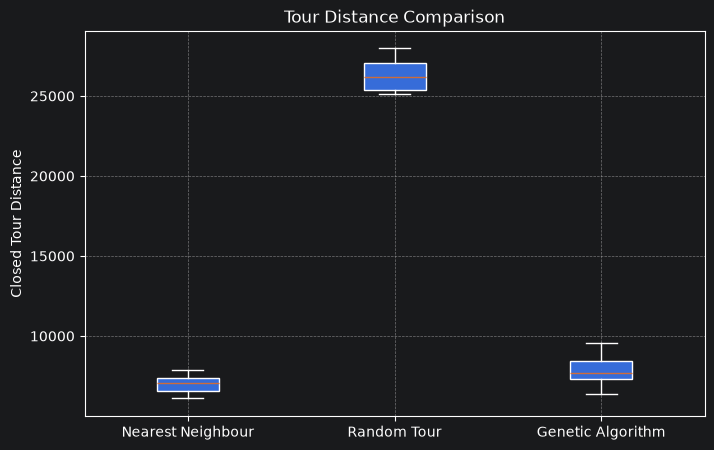

In [7]:
nn_results = read_all_tour_results(os.path.join(HW1_DIR, "results", "nearest_neighbour"))
rnd_results = read_all_tour_results(os.path.join(HW1_DIR, "results", "random_tour"))
ga_results = read_all_tour_results(os.path.join(HW1_DIR, "results", "genetic_algorithm"))

nn_dists = [r["distance"] for r in nn_results]
rnd_dists = [r["distance"] for r in rnd_results]
ga_dists = [r["distance"] for r in ga_results]

fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot([nn_dists, rnd_dists, ga_dists], tick_labels=["Nearest Neighbour", "Random Tour", "Genetic Algorithm"], patch_artist=True)
ax.set_title("Tour Distance Comparison")
ax.set_ylabel("Closed Tour Distance")
ax.grid(True, linestyle="--", alpha=0.6)
plt.show()


## 3. Genetic Algorithm II
While your Genetic Algorithm runs, display a live graph that updates after every generation. It should show the best, average, and worst solution. How does this graph change if you increase the selection pressure (e.g. increase tournament size). Does your result get better, stays the same or gets worse?


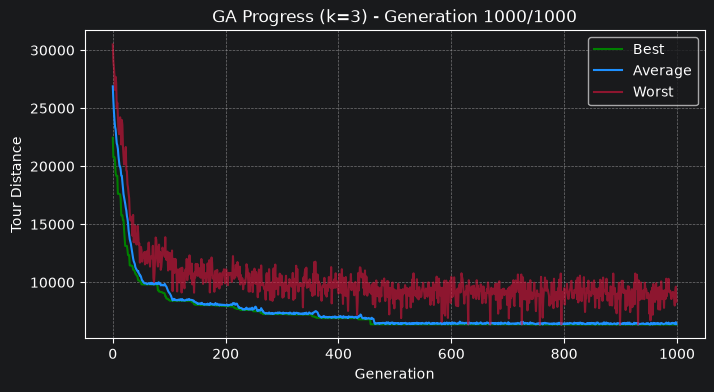

In [8]:
def run_ga_live_plot(points, pop_size=100, generations=1000, mutation_chance=0.05, elite_size=1, tournament_k=3, live=True, plot_every=50):
    random.seed(42)
    population = [random.sample(points, len(points)) for _ in range(pop_size)]
    best_history, avg_history, worst_history = [], [], []

    for gen in range(generations):
        distances = [Tour(ind).total_distance() for ind in population]
        best_history.append(min(distances))
        avg_history.append(sum(distances) / len(distances))
        worst_history.append(max(distances))

        if live and (gen % plot_every == 0 or gen == generations - 1):
            clear_output(wait=True)
            plt.figure(figsize=(8, 4))
            plt.plot(best_history, label="Best", color="green")
            plt.plot(avg_history, label="Average", color="dodgerblue")
            plt.plot(worst_history, label="Worst", color="crimson", alpha=0.6)
            plt.title(f"GA Progress (k={tournament_k}) - Generation {gen + 1}/{generations}")
            plt.xlabel("Generation")
            plt.ylabel("Tour Distance")
            plt.legend()
            plt.grid(True, linestyle="--", alpha=0.6)
            plt.show()

        sorted_indices = sorted(range(pop_size), key=lambda i: distances[i])
        new_population = [population[i].copy() for i in sorted_indices[:elite_size]]

        while len(new_population) < pop_size:
            p1 = tournament_selection(population, distances, k=tournament_k)
            p2 = tournament_selection(population, distances, k=tournament_k)
            child = ordered_crossover(p1, p2)
            child = swap_mutation(child, mutation_chance)
            new_population.append(child)

        population = new_population

    return best_history, avg_history, worst_history

# Set plot_every=1 to redraw on every single generation
best_k3, avg_k3, worst_k3 = run_ga_live_plot(instances[0], tournament_k=3, live=True, plot_every=50)


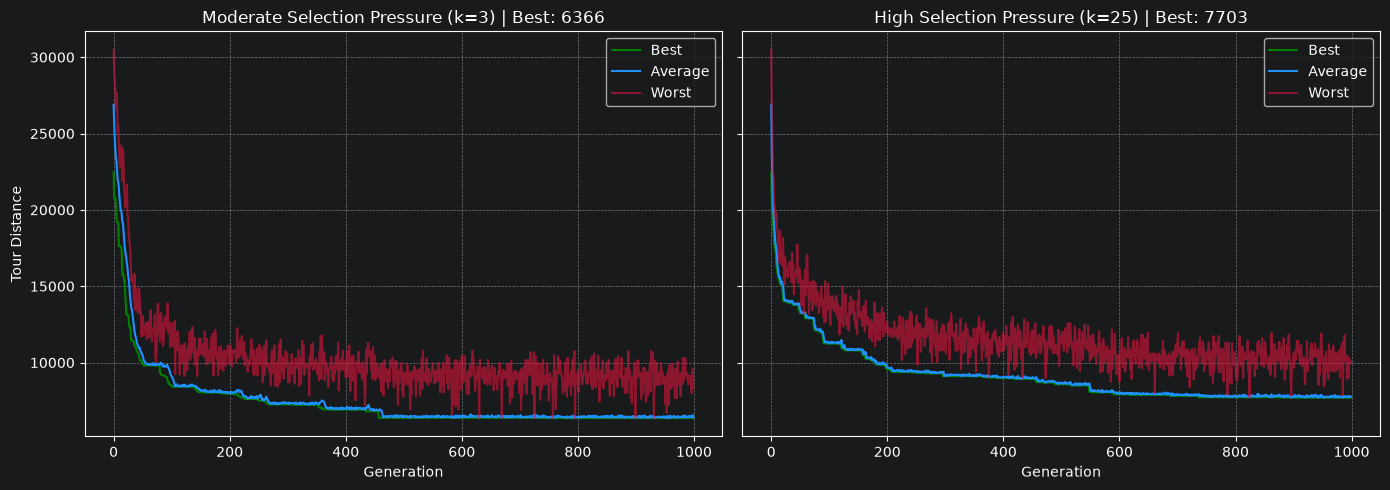

In [9]:

best_k25, avg_k25, worst_k25 = run_ga_live_plot(instances[0], tournament_k=25, live=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

axes[0].plot(best_k3, label="Best", color="green")
axes[0].plot(avg_k3, label="Average", color="dodgerblue")
axes[0].plot(worst_k3, label="Worst", color="crimson", alpha=0.6)
axes[0].set_title(f"Moderate Selection Pressure (k=3) | Best: {best_k3[-1]:.0f}")
axes[0].set_xlabel("Generation")
axes[0].set_ylabel("Tour Distance")
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.6)

axes[1].plot(best_k25, label="Best", color="green")
axes[1].plot(avg_k25, label="Average", color="dodgerblue")
axes[1].plot(worst_k25, label="Worst", color="crimson", alpha=0.6)
axes[1].set_title(f"High Selection Pressure (k=25) | Best: {best_k25[-1]:.0f}")
axes[1].set_xlabel("Generation")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()


### Observation on Selection Pressure
- **How the graph changes:** When increasing the tournament size (e.g. from `k=3` to `k=25`), the curves drop much steeper in the first few generations and the average fitness quickly collapses onto the best fitness line because almost all individuals become copies of the best solution.
- **Effect on the result:** Increasing selection pressure slightly (e.g. `k=2` to `k=3`) improves convergence, but making selection pressure too high (`k=25`) makes the final result **worse**. The population loses its genetic diversity too early and gets stuck in a local optimum.


## 4. Genetic Algorithm III
After every generation, write the currently best solution (your encoded solution, e.g. order of visiting the cities) to a file. Create a program that visualizes the result (2D). The program should wait 100 ms after every generation, before overwriting the current 2D visualization with a visualization of the next generation.


In [10]:
def run_ga_log_generations(points, filepath="generations_best.txt", pop_size=100, generations=1000, mutation_chance=0.05, elite_size=1, tournament_k=3):
    random.seed(42)
    population = [random.sample(points, len(points)) for _ in range(pop_size)]

    with open(filepath, "w", encoding="utf-8") as f:
        for _ in range(generations):
            distances = [Tour(ind).total_distance() for ind in population]
            sorted_indices = sorted(range(pop_size), key=lambda i: distances[i])
            best_ind = population[sorted_indices[0]]

            # Write best encoded solution (city IDs in visiting order) for this generation
            encoded_tour = " ".join(str(p.id) for p in best_ind)
            f.write(encoded_tour + "\n")

            new_population = [population[i].copy() for i in sorted_indices[:elite_size]]
            while len(new_population) < pop_size:
                p1 = tournament_selection(population, distances, k=tournament_k)
                p2 = tournament_selection(population, distances, k=tournament_k)
                child = ordered_crossover(p1, p2)
                child = swap_mutation(child, mutation_chance)
                new_population.append(child)
            population = new_population

run_ga_log_generations(instances[0], filepath="generations_best.txt")
print("Saved 1000 generations to generations_best.txt")


Saved 1000 generations to generations_best.txt


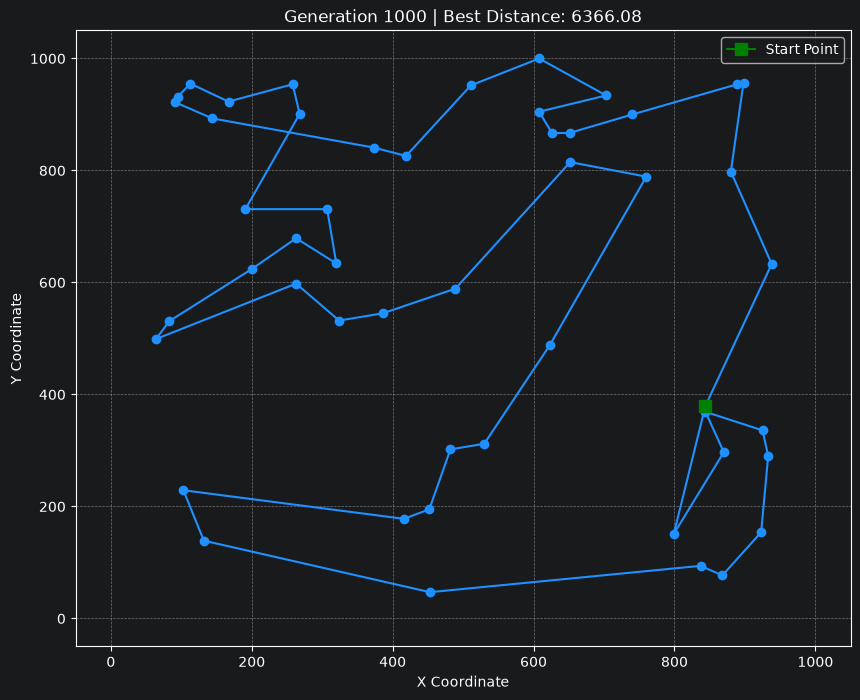

In [14]:
def visualize_generations_from_file(points, filepath="generations_best.txt", delay=0.1, step=50):
    point_map = {p.id: p for p in points}
    with open(filepath, "r", encoding="utf-8") as f:
        lines = [line.strip() for line in f if line.strip()]

    indices = list(range(0, len(lines), step))
    if indices[-1] != len(lines) - 1:
        indices.append(len(lines) - 1)

    for gen_idx in indices:
        ids = [int(x) for x in lines[gen_idx].split()]
        tour_points = [point_map[i] for i in ids]
        tour = Tour(tour_points)

        clear_output(wait=True)
        tour.plot(title=f"Generation {gen_idx + 1} | Best Distance: {tour.total_distance():.2f}")
        time.sleep(delay)

visualize_generations_from_file(instances[0], filepath="generations_best.txt", delay=0.1, step=50)
